# Modelagem: quais municípios cumprem a meta de alfabetização?

Tech Challenge, Fase 3 (Pós Tech). Segundo notebook do projeto.

Na EDA (`01_eda_hipoteses.ipynb`) vimos que o cumprimento da meta de 2024 depende pouco do ponto de partida e muito de como cada município se move de um ano para o outro, com um choque forte no Rio Grande do Sul. Aqui construímos o modelo supervisionado e medimos o quanto ele acerta. As perguntas de negócio ficam para o `03_aplicacao_estrategica.ipynb`.

O desenho é simples: um pipeline do Scikit-learn com o pré-processamento dentro do modelo, quatro candidatos comparados, ajuste do melhor e uma avaliação final em dados que o modelo nunca viu. O código reutilizável está em `src/`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report
from sklearn.model_selection import (GroupKFold, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, train_test_split)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.evaluation.metrics import metricas_teste, tabela_comparacao, valida_cruzado
from src.modeling.pipeline import GRADE_RANDOM_FOREST, SEED, busca_hiperparametros, candidatos, monta_pipeline
from src.preprocessing.features import ALVO, CATEGORICAS, NUMERICAS, carrega_abt, monta_features
from src.visualization import plots

set_config(display="text")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)

REPORTS = RAIZ / "reports"
REPORTS.mkdir(exist_ok=True)

## 1. Dados e escopo

A base é a ABT da Fase 3, com um município por linha, variáveis de 2023 e o target de 2024 (1 se a taxa de alfabetização ficou igual ou acima da meta). As variáveis do modelo são a taxa e a média de português de 2023, a participação na avaliação, o porte (log da população), o PIB per capita (log) e a macrorregião. O esforço exigido (meta menos taxa) ficou de fora: em 2024 a meta é função quase exata da taxa de 2023, então essa informação já está em `taxa_base`.

O Rio Grande do Sul fica fora do treino. Na EDA, 75% dos municípios gaúchos perderam mais de 10 p.p. em 2024, contra 12% no resto do país. Com o RS dentro, a macrorregião "Sul" aprende a ser sinônimo de risco e penaliza Santa Catarina e o Paraná por um choque que não é deles. A primeira linha da saída mostra a diferença: 33,9% dos municípios do Sul cumpriram a meta com o RS e 50,1% sem ele. O RS é analisado à parte, na seção 6.

In [2]:
abt = carrega_abt()
X_todos = monta_features(abt, ano_base=2023, ano_alvo=2024)
y_todos = abt[ALVO]

# o RS fica fora do treino: em 2024 se comportou como um choque (ver 01_eda_hipoteses)
rs = abt["sigla_uf"] == "RS"
sul = abt["macrorregiao"] == "Sul"
print(f"Sul: {y_todos[sul].mean():.1%} cumpriram a meta com o RS | {y_todos[sul & ~rs].mean():.1%} sem o RS")

X, y = X_todos[~rs], y_todos[~rs]
X_rs, y_rs = X_todos[rs], y_todos[rs]
print(f"modelagem: {len(X):,} municípios, {y.mean():.1%} cumpriram a meta de 2024 | RS (analisado à parte): {len(X_rs)}")
print("numéricas:", NUMERICAS)
print("categóricas:", CATEGORICAS)
print("valores nulos nas variáveis do modelo:", int(X[NUMERICAS + CATEGORICAS].isna().sum().sum()))
X[NUMERICAS].describe().round(1)

Sul: 33.9% cumpriram a meta com o RS | 50.1% sem o RS
modelagem: 4,811 municípios, 57.1% cumpriram a meta de 2024 | RS (analisado à parte): 421
numéricas: ['taxa_base', 'media_portugues_base', 'participacao_base', 'log_populacao', 'log_pib_per_capita']
categóricas: ['macrorregiao']
valores nulos nas variáveis do modelo: 0


,taxa_base,media_portugues_base,participacao_base,log_populacao,log_pib_per_capita
count,4811.0,4811.0,4811.0,4811.0,4811.0
mean,59.4,750.2,90.0,9.5,10.3
std,19.8,25.1,6.1,1.2,0.7
min,4.4,673.3,70.0,6.8,8.9
25%,45.3,733.7,86.4,8.7,9.7
50%,59.5,748.7,90.8,9.4,10.2
75%,73.8,763.5,94.6,10.2,10.7
max,100.0,868.5,100.0,16.3,13.4


Ficam 4.811 municípios para a modelagem, dos quais 57,1% cumpriram a meta. O target é equilibrado o bastante para dispensar reamostragem. Não há valores ausentes nas variáveis escolhidas, mas o imputador continua no pipeline, porque dados futuros podem chegar incompletos.

## 2. Separação dos dados e vazamento

Separamos 20% para teste (963 municípios), de forma estratificada pelo target e com semente fixa. Esses dados só são usados no fim. Todo o resto usa os 3.848 municípios de treino, com validação cruzada.

Contra o vazamento de dados há duas frentes. A primeira é a escolha das variáveis: só entram colunas de 2023 e a meta, e `monta_features` recusa um ano-base que não seja anterior ao ano-alvo. A segunda é o pipeline: imputação, escala e codificação ficam dentro do `Pipeline`, então cada fold ajusta essas transformações só com o seu treino. Para mostrar o tamanho do problema que isso evita, a célula abaixo repete a validação com a taxa de 2024 incluída como variável.

In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"treino: {len(X_treino):,} ({y_treino.mean():.1%} cumprem) | teste: {len(X_teste):,} ({y_teste.mean():.1%} cumprem)")

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
gbc = candidatos()["Gradient boosting"]

# demonstração: o que acontece se uma coluna de 2024 entra como variável
vazado = X_treino.assign(taxa_2024=abt.loc[X_treino.index, "taxa_alfabetizacao_2024_pct"])
auc_limpo = cross_val_score(monta_pipeline(gbc), X_treino, y_treino, cv=cv, scoring="roc_auc").mean()
auc_vazado = cross_val_score(monta_pipeline(gbc, NUMERICAS + ["taxa_2024"]), vazado, y_treino, cv=cv, scoring="roc_auc").mean()
print(f"AUC sem vazamento: {auc_limpo:.3f} | com a taxa de 2024 como variável: {auc_vazado:.3f}")

treino: 3,848 (57.1% cumprem) | teste: 963 (57.1% cumprem)
AUC sem vazamento: 0.697 | com a taxa de 2024 como variável: 0.997


O AUC sobe de 0,70 para 0,997 quando a taxa de 2024 entra. Um resultado perfeito demais é o que um vazamento produz, e é por isso que a lista `COLUNAS_ANO_ALVO` existe no script que constrói a ABT.

## 3. O pipeline

O pré-processamento e o modelo formam um único objeto. As variáveis numéricas passam por imputação pela mediana e padronização. A macrorregião passa por imputação pela moda e one-hot encoding, ignorando categorias novas. Trocar o algoritmo não muda nada além da última etapa.

In [4]:
print(monta_pipeline(candidatos()["Gradient boosting"]))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputa',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('escala',
                                                                   StandardScaler())]),
                                                  ['taxa_base',
                                                   'media_portugues_base',
                                                   'participacao_base',
                                                   'log_populacao',
                                                   'log_pib_per_capita']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputa',
                                                                   SimpleImputer(strat

## 4. Comparando modelos

Comparamos quatro candidatos na mesma validação cruzada (5 folds repetidos 2 vezes): um baseline que sempre prevê a classe majoritária, a regressão logística, a random forest e o gradient boosting. Entre as métricas estão a precisão e o recall da classe "não cumpre a meta", que é a que importa para a política pública: deixar passar um município que não cumpre custa mais do que apontar um que cumpriria.

In [5]:
resultados = {}
for nome, modelo in candidatos().items():
    resultados[nome] = valida_cruzado(monta_pipeline(modelo), X_treino, y_treino, cv)
tabela_comparacao(resultados)

,AUC,± AUC,AUC treino,AP,F1,precisão (não cumpre),recall (não cumpre)
modelo,,,,,,,
Baseline (classe majoritária),0.500,0.000,0.500,0.571,0.727,0.000,0.000
Regressão logística,0.680,0.006,0.684,0.721,0.714,0.614,0.487
Random forest,0.708,0.014,0.892,0.764,0.725,0.634,0.500
Gradient boosting,0.697,0.014,0.815,0.750,0.725,0.633,0.471


A regressão logística (AUC 0,680) fica abaixo dos dois modelos de árvores, que ficam próximos: random forest com 0,708 e gradient boosting com 0,697. O ganho sobre o baseline é claro, mas moderado. O AUC de treino da random forest (0,89) é muito acima do de validação. Isso é esperado nesse algoritmo, porque cada árvore já viu a maior parte dos dados que depois são usados para pontuar o treino. O número que vale é o de validação.

## 5. Ajuste de hiperparâmetros

Ajustamos a random forest, que teve o melhor AUC, com busca aleatória (12 combinações, validação cruzada de 5 folds, AUC como critério). Limitar a profundidade e o tamanho mínimo das folhas é a forma mais direta de reduzir o overfitting.

In [6]:
cv_busca = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
busca = busca_hiperparametros(monta_pipeline(candidatos()["Random forest"]), GRADE_RANDOM_FOREST,
                              X_treino, y_treino, cv_busca)
modelo_final = busca.best_estimator_
parametros = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
print("melhores parâmetros:", parametros)

ajustado = valida_cruzado(modelo_final, X_treino, y_treino, cv)
tabela_comparacao({**resultados, "Random forest (ajustado)": ajustado})

melhores parâmetros: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 8}


,AUC,± AUC,AUC treino,AP,F1,precisão (não cumpre),recall (não cumpre)
modelo,,,,,,,
Baseline (classe majoritária),0.500,0.000,0.500,0.571,0.727,0.000,0.000
Regressão logística,0.680,0.006,0.684,0.721,0.714,0.614,0.487
Random forest,0.708,0.014,0.892,0.764,0.725,0.634,0.500
Gradient boosting,0.697,0.014,0.815,0.750,0.725,0.633,0.471
Random forest (ajustado),0.708,0.014,0.881,0.761,0.725,0.635,0.493


O ajuste não mexeu no AUC de validação (0,708 antes e depois), então o limite parece estar nas informações disponíveis e não nos hiperparâmetros. A diferença para o gradient boosting está dentro do desvio entre folds (0,014), e seguimos com a random forest (300 árvores, profundidade máxima 8, folhas de pelo menos 5 municípios).

## 6. Generalização e replicabilidade

Um AUC de validação não basta. Queremos saber se ele se mantém quando a semente muda, quando a geografia sai do modelo e quando o modelo precisa prever em estados que não viu. O RS, que nunca entrou no treino, serve de teste extremo.

In [7]:
ref = ajustado["auc"]
print(f"AUC no treino: {ajustado['auc_treino']:.3f} | na validação: {ref:.3f}")

# 1) mesma validação com cinco sementes diferentes
por_semente = [
    cross_val_score(clone(modelo_final), X_treino, y_treino, scoring="roc_auc",
                    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=1, random_state=s)).mean()
    for s in range(5)
]
# 2) estados inteiros fora do treino de cada fold
por_uf = cross_val_score(clone(modelo_final), X_treino, y_treino, scoring="roc_auc",
                         cv=GroupKFold(n_splits=5), groups=X_treino["sigla_uf"])
# 3) sem a macrorregião
sem_geo = monta_pipeline(clone(modelo_final.named_steps["modelo"]), NUMERICAS, [])
auc_sem_geo = cross_val_score(sem_geo, X_treino, y_treino, cv=cv, scoring="roc_auc").mean()

# o RS nunca entrou no treino: o modelo enxerga a queda de 2024?
p_rs = modelo_final.predict_proba(X_rs)[:, 1]
print(f"RS ({len(X_rs)} municípios): probabilidade média prevista de cumprir = {p_rs.mean():.1%} | observado = {y_rs.mean():.1%}\n")

pd.DataFrame({
    "AUC": [ref, np.mean(por_semente), por_uf.mean(), auc_sem_geo],
    "variação": [0, np.std(por_semente), por_uf.std(), np.nan],
}, index=["validação de referência (10 folds)", "5 sementes diferentes (média e desvio)",
          "estados inteiros fora do treino (GroupKFold)", "sem a macrorregião"]).round(3)

AUC no treino: 0.881 | na validação: 0.708
RS (421 municípios): probabilidade média prevista de cumprir = 52.4% | observado = 9.5%



,AUC,variação
validação de referência (10 folds),0.708,0.000
5 sementes diferentes (média e desvio),0.705,0.003
estados inteiros fora do treino (GroupKFold),0.596,0.008
sem a macrorregião,0.658,NaN


Com cinco sementes diferentes o AUC fica em 0,705, com desvio de 0,003, então o resultado é replicável. Sem a macrorregião o AUC cai para 0,658, ou seja, a geografia acrescenta cerca de 0,05. E com estados inteiros fora do treino (GroupKFold por UF) cai para cerca de 0,60. Esse é o número mais importante do bloco: boa parte do que o modelo sabe é como cada região se comportou em 2024, e isso se transfere mal para um estado novo.

O RS reforça o ponto. O modelo previu que 52,4% dos municípios gaúchos cumpririam a meta, e o observado foi 9,5%. Ele não tinha como antecipar a queda.

## 7. Avaliação no conjunto de teste

Aqui os dados de teste são usados pela primeira vez.

In [8]:
p_teste = modelo_final.predict_proba(X_teste)[:, 1]
met = metricas_teste(y_teste, p_teste)
pred = (p_teste >= 0.5).astype(int)

print(f"Random forest no teste: AUC {met['auc']:.3f} | acurácia {met['acuracia']:.3f} "
      f"(baseline: {max(y_teste.mean(), 1 - y_teste.mean()):.3f})\n")
print(classification_report(y_teste, pred, target_names=["não cumpre", "cumpre"], digits=3))

Random forest no teste: AUC 0.708 | acurácia 0.673 (baseline: 0.571)

              precision    recall  f1-score   support

  não cumpre      0.664     0.479     0.557       413
      cumpre      0.677     0.818     0.741       550

    accuracy                          0.673       963
   macro avg      0.671     0.649     0.649       963
weighted avg      0.671     0.673     0.662       963



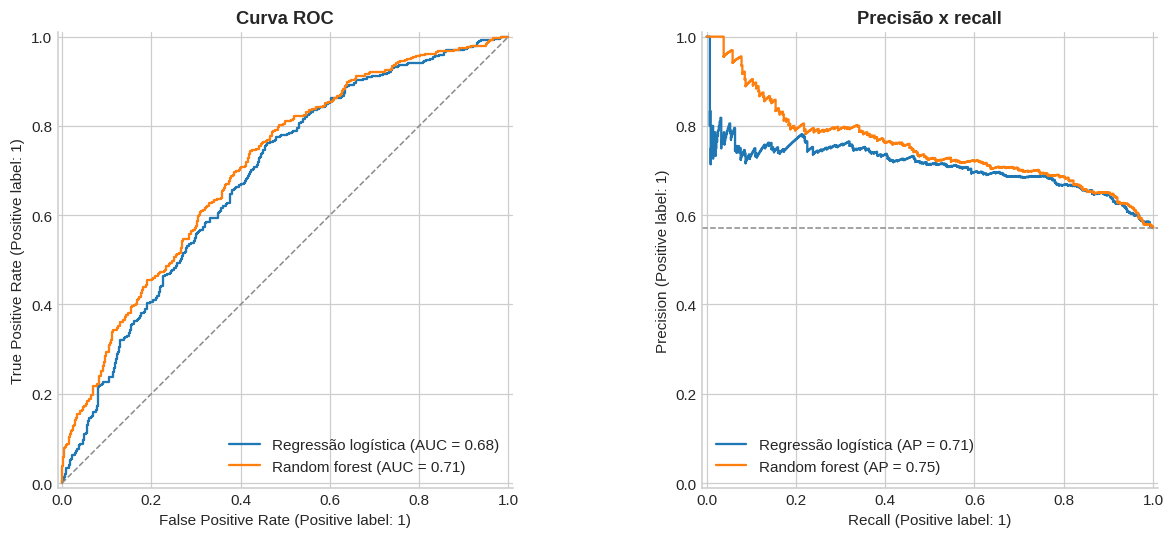

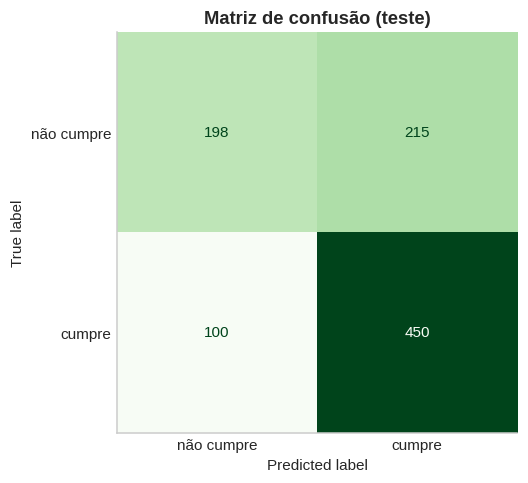

In [9]:
lr = monta_pipeline(candidatos()["Regressão logística"]).fit(X_treino, y_treino)
fig = plots.curvas_roc_pr(y_teste, {"Regressão logística": lr.predict_proba(X_teste)[:, 1], "Random forest": p_teste})
plots.salva(fig, "06_roc_pr_teste.png")
fig2 = plots.matriz_confusao(y_teste, pred)
plots.salva(fig2, "07_matriz_confusao.png")

O AUC de teste (0,708) coincide com o de validação, sem sinal de que o ajuste tenha se acomodado ao treino. A acurácia é de 67%, contra 57% do baseline. O ponto fraco está na classe de interesse: com o limiar de 0,5 o modelo encontra 48% dos municípios que não cumprem a meta (recall) e acerta 66% das vezes em que aponta um (precisão). Para uma política de busca ativa, valeria baixar o limiar e aceitar mais alarmes falsos. Não fizemos isso aqui para não ajustar o limiar olhando o teste.

## 8. O que pesa na previsão

Usamos a importância por permutação no teste (queda do AUC quando embaralhamos a variável) e o SHAP. A permutação trata a macrorregião como uma coluna só, e o SHAP a mostra dividida nas colunas do one-hot encoding.

,queda_do_auc,desvio
macrorregiao,0.1098,0.0122
participacao_base,0.0663,0.0081
taxa_base,0.0526,0.0091
media_portugues_base,0.0428,0.0071
log_populacao,0.0260,0.0068
log_pib_per_capita,-0.0039,0.0044


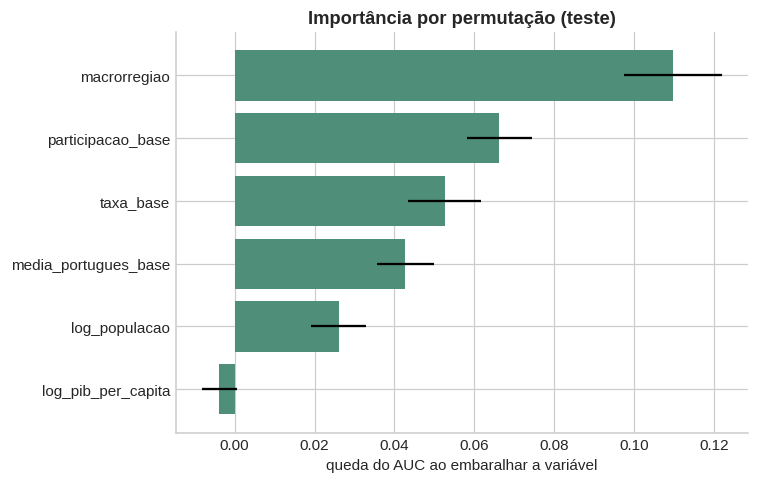

In [10]:
colunas = NUMERICAS + CATEGORICAS
perm = permutation_importance(modelo_final, X_teste[colunas], y_teste, scoring="roc_auc", n_repeats=30, random_state=SEED)
importancia = (pd.DataFrame({"queda_do_auc": perm.importances_mean, "desvio": perm.importances_std}, index=colunas)
               .sort_values("queda_do_auc", ascending=False))
importancia.to_csv(REPORTS / "importancia_variaveis.csv")

ordem = importancia["queda_do_auc"].sort_values().index
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(ordem, importancia.loc[ordem, "queda_do_auc"], xerr=importancia.loc[ordem, "desvio"], color=plots.COR_SIM)
ax.set_xlabel("queda do AUC ao embaralhar a variável")
ax.set_title("Importância por permutação (teste)")
plt.tight_layout()
plots.salva(fig, "08_importancia_variaveis.png")
importancia.round(4)

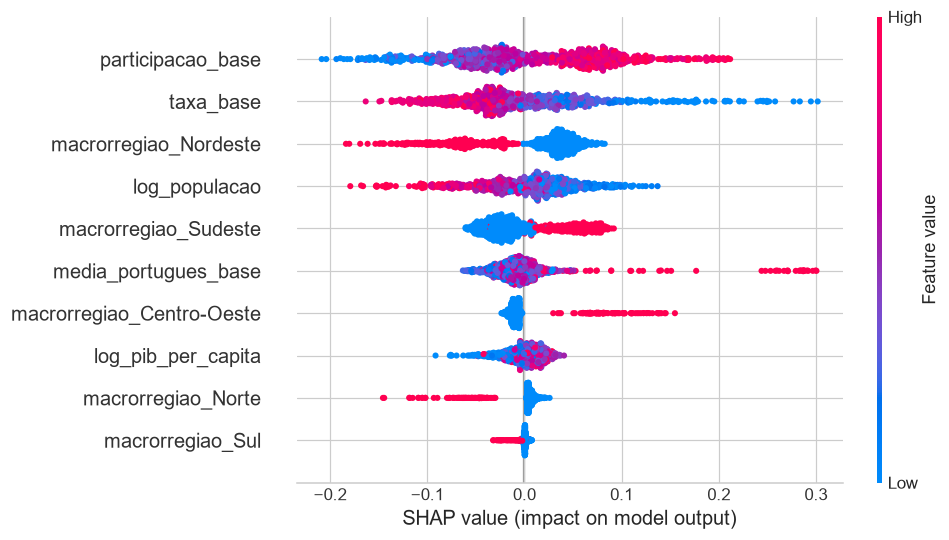

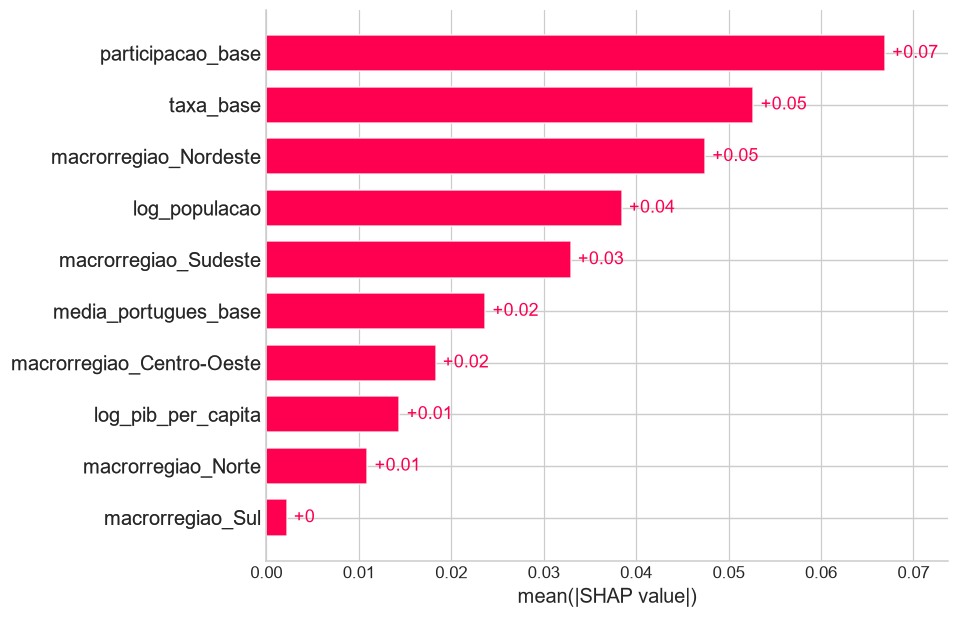

In [11]:
try:
    import shap
except ImportError:
    shap = None
    print("shap não está instalado neste ambiente (pip install shap). Rode esta célula depois de instalar.")

if shap is not None:
    prep = modelo_final.named_steps["prep"]
    nomes = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
    X_teste_t = pd.DataFrame(prep.transform(X_teste[colunas]), columns=nomes)
    explicador = shap.TreeExplainer(modelo_final.named_steps["modelo"])
    valores = explicador(X_teste_t)
    if valores.values.ndim == 3:  # a random forest devolve uma camada por classe
        valores = valores[:, :, 1]
    shap.plots.beeswarm(valores, show=False)
    plots.salva(plt.gcf(), "10_shap_beeswarm.png")
    plt.show()
    shap.plots.bar(valores, show=False)
    plots.salva(plt.gcf(), "10_shap_importancia.png")
    plt.show()

Na permutação, a macrorregião lidera (queda de 0,110 no AUC), seguida pela participação (0,066), pela taxa de 2023 (0,053), pela média de português (0,043) e pelo porte (0,026). O PIB per capita não contribui (−0,004, dentro do ruído), o que confirma a leitura da EDA: renda explica o nível da taxa, mas não o cumprimento da meta. Parte do peso da macrorregião é o desempenho de cada região em 2024 (o avanço de Minas Gerais, por exemplo) e não uma propriedade estável da região.

O SHAP mostra, para cada município, quanto cada variável empurrou a previsão. Lido por coluna, a participação lidera (impacto absoluto médio de 0,067), seguida pela taxa de 2023 (0,052), pela macrorregião Nordeste (0,047) e pelo porte (0,038). Somadas, as colunas de geografia pesam mais do que qualquer outra variável, o que concorda com a permutação. No beeswarm, participação alta empurra para o cumprimento da meta e participação baixa empurra para o contrário. Taxa de partida alta puxa para baixo e taxa baixa puxa para cima, que é a regressão à média. Municípios maiores têm impacto negativo. Estar no Nordeste ou no Norte reduz a probabilidade de cumprir, e estar no Sudeste ou no Centro-Oeste aumenta. O PIB per capita tem impacto pequeno (0,014). O Sul quase não tem efeito (0,002), o que mostra que deixar o RS fora do treino evitou que a macrorregião virasse sinônimo de risco.

## 9. Artefatos, resumo e limitações

Salvamos em `reports/` o modelo treinado com todos os municípios da modelagem, a comparação de modelos, as métricas finais e a importância das variáveis.

In [12]:
modelo_producao = clone(modelo_final).fit(X, y)   # treina com todos os municípios da modelagem (sem o RS)
joblib.dump(modelo_producao, REPORTS / "modelo_final.joblib")
tabela_comparacao({**resultados, "Random forest (ajustado)": ajustado}).to_csv(REPORTS / "comparacao_modelos.csv")

resumo = {
    "modelo": "Random forest",
    "parametros": parametros,
    "auc_validacao_cruzada": round(float(ref), 4),
    "teste": {k: round(float(v), 4) for k, v in met.items()},
    "semente": SEED,
}
(REPORTS / "metricas_modelo_final.json").write_text(json.dumps(resumo, indent=2, default=str, ensure_ascii=False))
resumo

{'modelo': 'Random forest', 'parametros': {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 8}, 'auc_validacao_cruzada': 0.7078, 'teste': {'auc': 0.7081, 'ap': 0.7541, 'f1': 0.7407, 'precisao_nao_cumpre': 0.6644, 'recall_nao_cumpre': 0.4794, 'acuracia': 0.6729}, 'semente': 42}

Com informação de um único ano anterior, dá para prever o cumprimento da meta com AUC de cerca de 0,71. É bem acima do acaso (0,50), mas longe de um modelo preciso. Os fatores que mais pesam são a participação na avaliação, a taxa de partida e o porte do município. A renda não pesa, e a geografia pesa muito, em parte por causa de choques específicos de 2024.

Limitações a registrar:

* O treino usa um único par de anos (2023 e 2024). Não há como separar tendência de choque nem testar o modelo em outro ano.
* A geografia é instável: com estados inteiros fora do treino o AUC cai para cerca de 0,60, e a macrorregião reflete parcialmente o desempenho de 2024.
* O RS ficou fora do treino por decisão analítica. O modelo não antecipa o choque (previu 52% de cumprimento onde o observado foi 9,5%), e a hipótese da enchente não pôde ser testada com os dados disponíveis.
* No limiar de 0,5 o recall da classe "não cumpre" é de 48%.